# Exploratory Data Analysis

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [2]:
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt

## Load Data
Load data and select features with an SQL query through the duckdb.

In [3]:
con = duckdb.connect("lol_predictors.duckdb")

def data_selection(df, included_cols):
    # Choose the dataset using an SQL query
    df = con.execute(f"""
    SELECT {", ".join(included_cols)}
    FROM {df}
    WHERE position = 'team';
    """).df()

    return df

# Adjust list based on the features considered
cols_to_include = ['gameid', 'league', 'year', 'split', 'patch',
                   'teamname', 'gamelength', 'result', 'kills',
                   'deaths', 'assists', 'towers', 'dpm', 'damagetakenperminute',
                   'wardskilled', 'totalgold', 'goldspent'
                   ]

df_selected = "df_2014" # temporarily hardcoded df name
df = data_selection(df_selected, cols_to_include)

con.close()

### Data Overview

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1836 entries, 0 to 1835
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gameid                1836 non-null   str    
 1   league                1836 non-null   str    
 2   year                  1836 non-null   int64  
 3   split                 1680 non-null   str    
 4   patch                 1478 non-null   float64
 5   teamname              1836 non-null   str    
 6   gamelength            1836 non-null   int64  
 7   result                1836 non-null   int64  
 8   kills                 1836 non-null   int64  
 9   deaths                1836 non-null   int64  
 10  assists               1836 non-null   int64  
 11  towers                1836 non-null   float64
 12  dpm                   1836 non-null   float64
 13  damagetakenperminute  1836 non-null   float64
 14  wardskilled           1836 non-null   int64  
 15  totalgold             1836 non-n

In [5]:
df.shape

(1836, 17)

In [6]:
df.describe()

,year,patch,gamelength,result,kills,deaths,assists,towers,dpm,damagetakenperminute,wardskilled,totalgold,goldspent
count,1836.000000,1478.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000,1836.000000
mean,2014.113290,4.091083,2281.938998,0.500000,13.464052,13.486928,31.408497,6.459150,1897.535525,2688.462071,27.109477,61644.996187,54810.416667
std,0.317033,0.129632,518.344662,0.500136,7.458098,7.458904,19.057887,3.412266,467.734221,460.097915,13.230487,15686.132262,15237.440733
min,2014.000000,3.150000,1218.000000,0.000000,0.000000,0.000000,0.000000,0.000000,595.044900,1323.739500,1.000000,23991.000000,20583.000000
25%,2014.000000,4.070000,1920.000000,0.000000,7.000000,8.000000,16.000000,3.000000,1569.569325,2366.829975,17.000000,50453.750000,43937.000000
50%,2014.000000,4.110000,2220.500000,0.500000,13.000000,13.000000,30.000000,7.000000,1880.978450,2675.609300,25.000000,61117.000000,53084.000000
75%,2014.000000,4.140000,2569.000000,1.000000,18.000000,18.000000,45.000000,10.000000,2200.015275,2979.522800,35.000000,71823.750000,63962.750000
max,2015.000000,4.210000,4837.000000,1.000000,51.000000,51.000000,142.000000,11.000000,3802.547300,4663.127400,87.000000,129459.000000,127251.000000


# Data Audit

In [7]:
def data_profiling(df, df_selected=df_selected):
    """
    Present the profile of the dataframe, including
    description, number of missing values, number of unique values, and unique values of object series
    """    
    with pd.option_context('display.max_seq_items', None): # list all columns of the df with no limits
        print(f"List of Columns: {df.columns}")
    
    with pd.option_context('display.max_rows', None): # list all rows of the df with no limits
        # State the number of missing items for each column
        print(f"\n{" COUNT OF MISSING VALUES ":-^50}") 
        display(df.isnull().sum())

        print(f"\n{" COUNT OF UNIQUE VALUES ":-^50}")
        display(df.nunique())

        print(f"\n{" UNIQUE VALUES OF OBJECT SERIES ":-^50}")
        for object_column in df.select_dtypes(include=['object']):
            if object_column == 'gameid': # skip gameid series
                continue
            print("\n",df[object_column].value_counts())


In [8]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'year', 'split', 'patch', 'teamname', 'gamelength',
       'result', 'kills', 'deaths', 'assists', 'towers', 'dpm',
       'damagetakenperminute', 'wardskilled', 'totalgold', 'goldspent'],
      dtype='str')

------------ COUNT OF MISSING VALUES -------------


gameid                    0
league                    0
year                      0
split                   156
patch                   358
teamname                  0
gamelength                0
result                    0
kills                     0
deaths                    0
assists                   0
towers                    0
dpm                       0
damagetakenperminute      0
wardskilled               0
totalgold                 0
goldspent                 0
dtype: int64


------------- COUNT OF UNIQUE VALUES -------------


gameid                   918
league                     5
year                       2
split                      2
patch                     15
teamname                  81
gamelength               712
result                     2
kills                     41
deaths                    41
assists                   91
towers                    12
dpm                     1836
damagetakenperminute    1835
wardskilled               75
totalgold               1805
goldspent               1780
dtype: int64


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
NA LCS    672
EU LCS    650
NA CS     184
EU CS     174
WLDs      156
Name: count, dtype: int64

 split
Spring    884
Summer    796
Name: count, dtype: int64

 teamname
TSM                       86
Cloud9                    80
Alliance                  78
SK Gaming                 78
Fnatic                    77
Counter Logic Gaming      75
Team Curse                74
Team Coast                73
Millenium                 72
Team ROCCAT               71
Dignitas                  70
Copenhagen Wolves         67
LMQ                       65
Gambit Gaming             64
SUPA HOT CREW             64
Evil Geniuses             63
Curse Academy             44
Ninjas in Pyjamas         39
Reason Gaming             36
XDG Gaming                33
compLexity Gaming         33
H2k-Gaming                29
Team LoLPro               28
SK Gaming Prime           27
Team 8                    23
Gamers2                   22
Royal Club      

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19452\581957970.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for object_column in df.select_dtypes(include=['object']):


In [9]:
def count_outliers(df, IQR_multiplier=1.5):
    """
    Utilizes IQR to detect outliers.
    """
    # Define numerical columns
    num_cols = df.select_dtypes(include=["number"]).columns.drop(['year', 'patch', 'result']).tolist()

    print(f"\n{" COUNT OF OUTLIERS ":-^50}")
    for col in num_cols:
        # Setting the IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        # Standard 1.5 multiplier for outlier bounds
        lower_bound = Q1 - IQR_multiplier * IQR
        upper_bound = Q3 + IQR_multiplier * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        print(f"{f"{col}:":<23} {len(outliers):>5} ({len(outliers)/len(df[col]):<.2%})")

In [10]:
count_outliers(df)


--------------- COUNT OF OUTLIERS ----------------
gamelength:                32 (1.74%)
kills:                     11 (0.60%)
deaths:                    18 (0.98%)
assists:                    8 (0.44%)
towers:                     0 (0.00%)
dpm:                       21 (1.14%)
damagetakenperminute:      19 (1.03%)
wardskilled:               21 (1.14%)
totalgold:                 15 (0.82%)
goldspent:                 23 (1.25%)


# Data Visualisation

In [11]:
# Define numerical columns to visualize
num_cols = df.select_dtypes(include=["number"]).columns.drop(['year', 'patch', 'result']).tolist()

# Define categorical columns to visualize
cat_cols = df.select_dtypes(include=["str"]).columns.drop(['gameid']).tolist()

In [12]:
def visualize_outliers(df, cols, plot_title="BOXPLOTS OF NUMERICAL COLUMNS", nrows=3, ncols=4, figsize=(16, 12)):
    """
    Utilize box plots to detect outliers.
    """
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize) # Adjust depending on the number of numerical columns
    axes = axes.flatten()
    fig.suptitle(plot_title.upper(), fontsize=16, fontweight="bold", y=1.02)

    for i, col in enumerate(cols):
        sns.boxplot(y=df[col], ax=axes[i])
        axes[i].set_title(col, fontsize=12, fontweight="bold")
        axes[i].set_ylabel("")

    # Hide unused subplots
    for j in range(len(cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

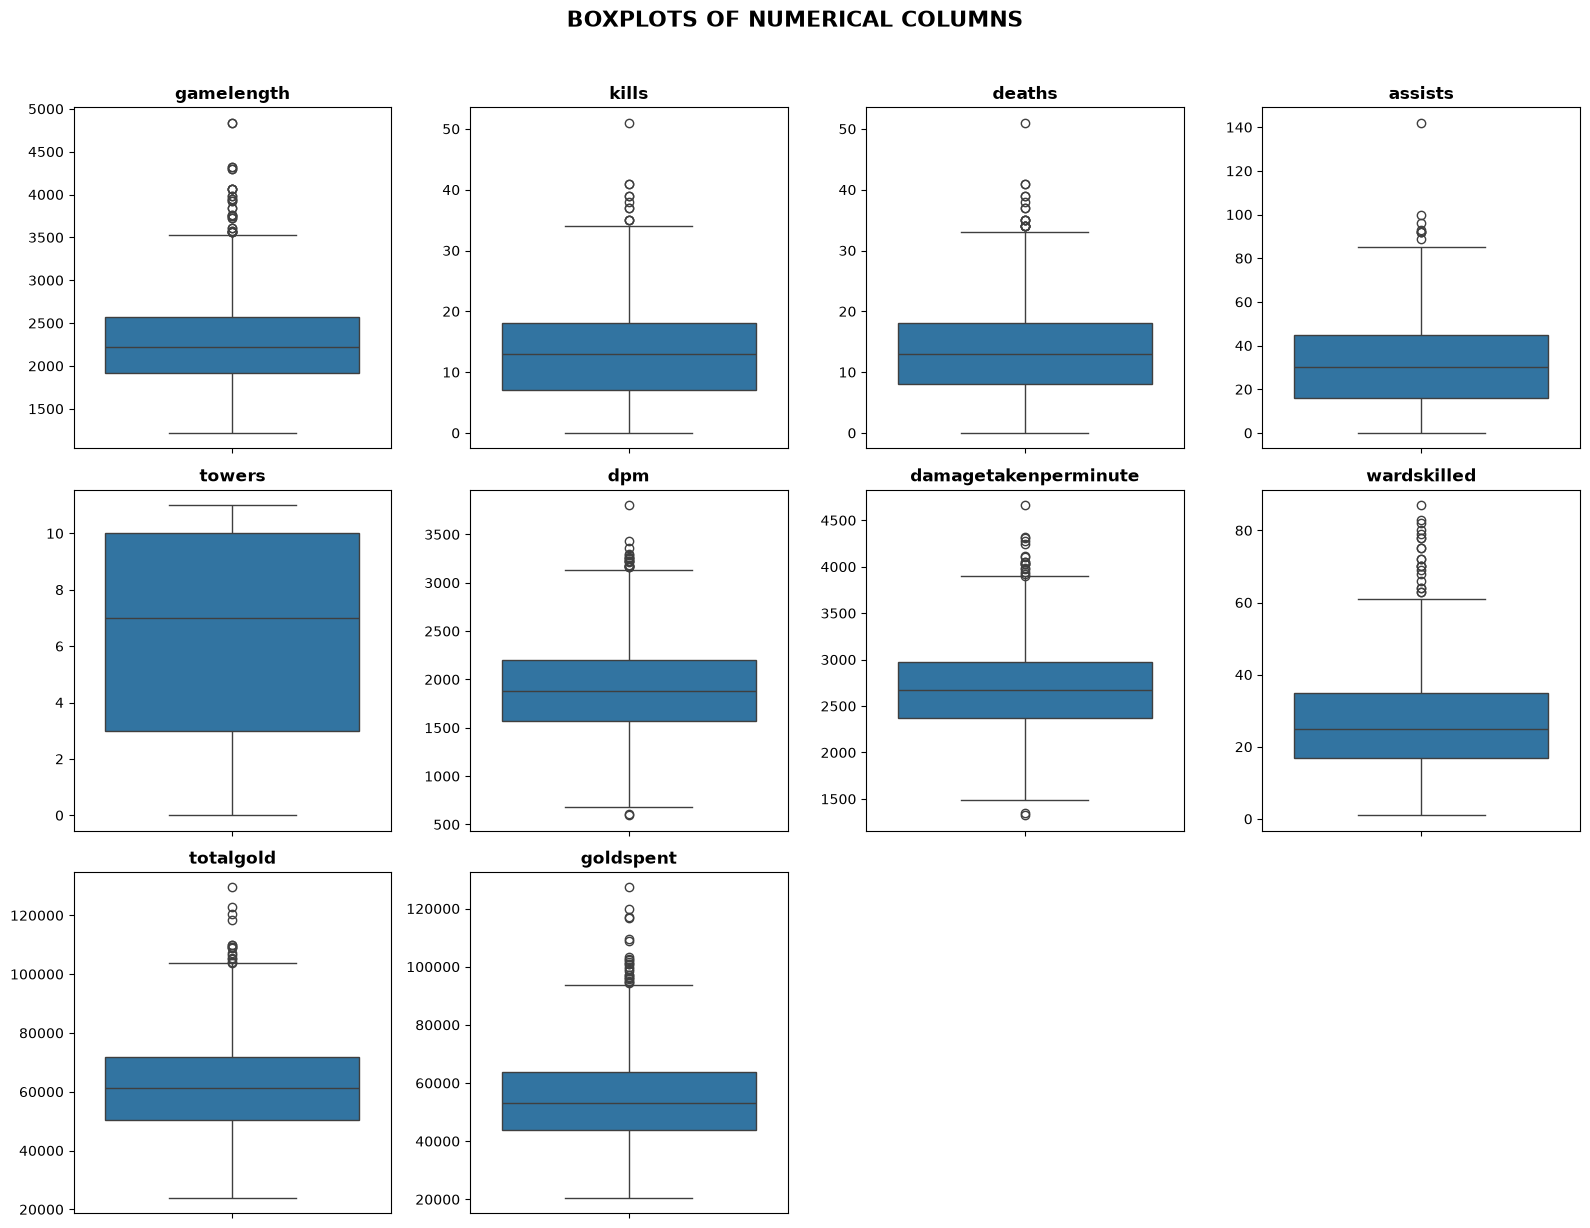

In [13]:
visualize_outliers(df, num_cols)

In [14]:
def visualize_num_distribution(df, cols, plot_title="DISTRIBUTION OF NUMERICAL COLUMNS", nrows=3, ncols=4, figsize=(16, 12)):
    """
    Utilize histograms to visualize numerical distribution.
    """
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize) # Adjust depending on the number of numerical columns
    axes = axes.flatten()
    fig.suptitle(plot_title.upper(), fontsize=16, fontweight="bold", y=1.02)

    for i, col in enumerate(cols):
        sns.histplot(x=df[col], ax=axes[i])
        axes[i].set_title(col, fontsize=12, fontweight="bold")
        axes[i].set_xlabel("")

    # Hide unused subplots
    for j in range(len(cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

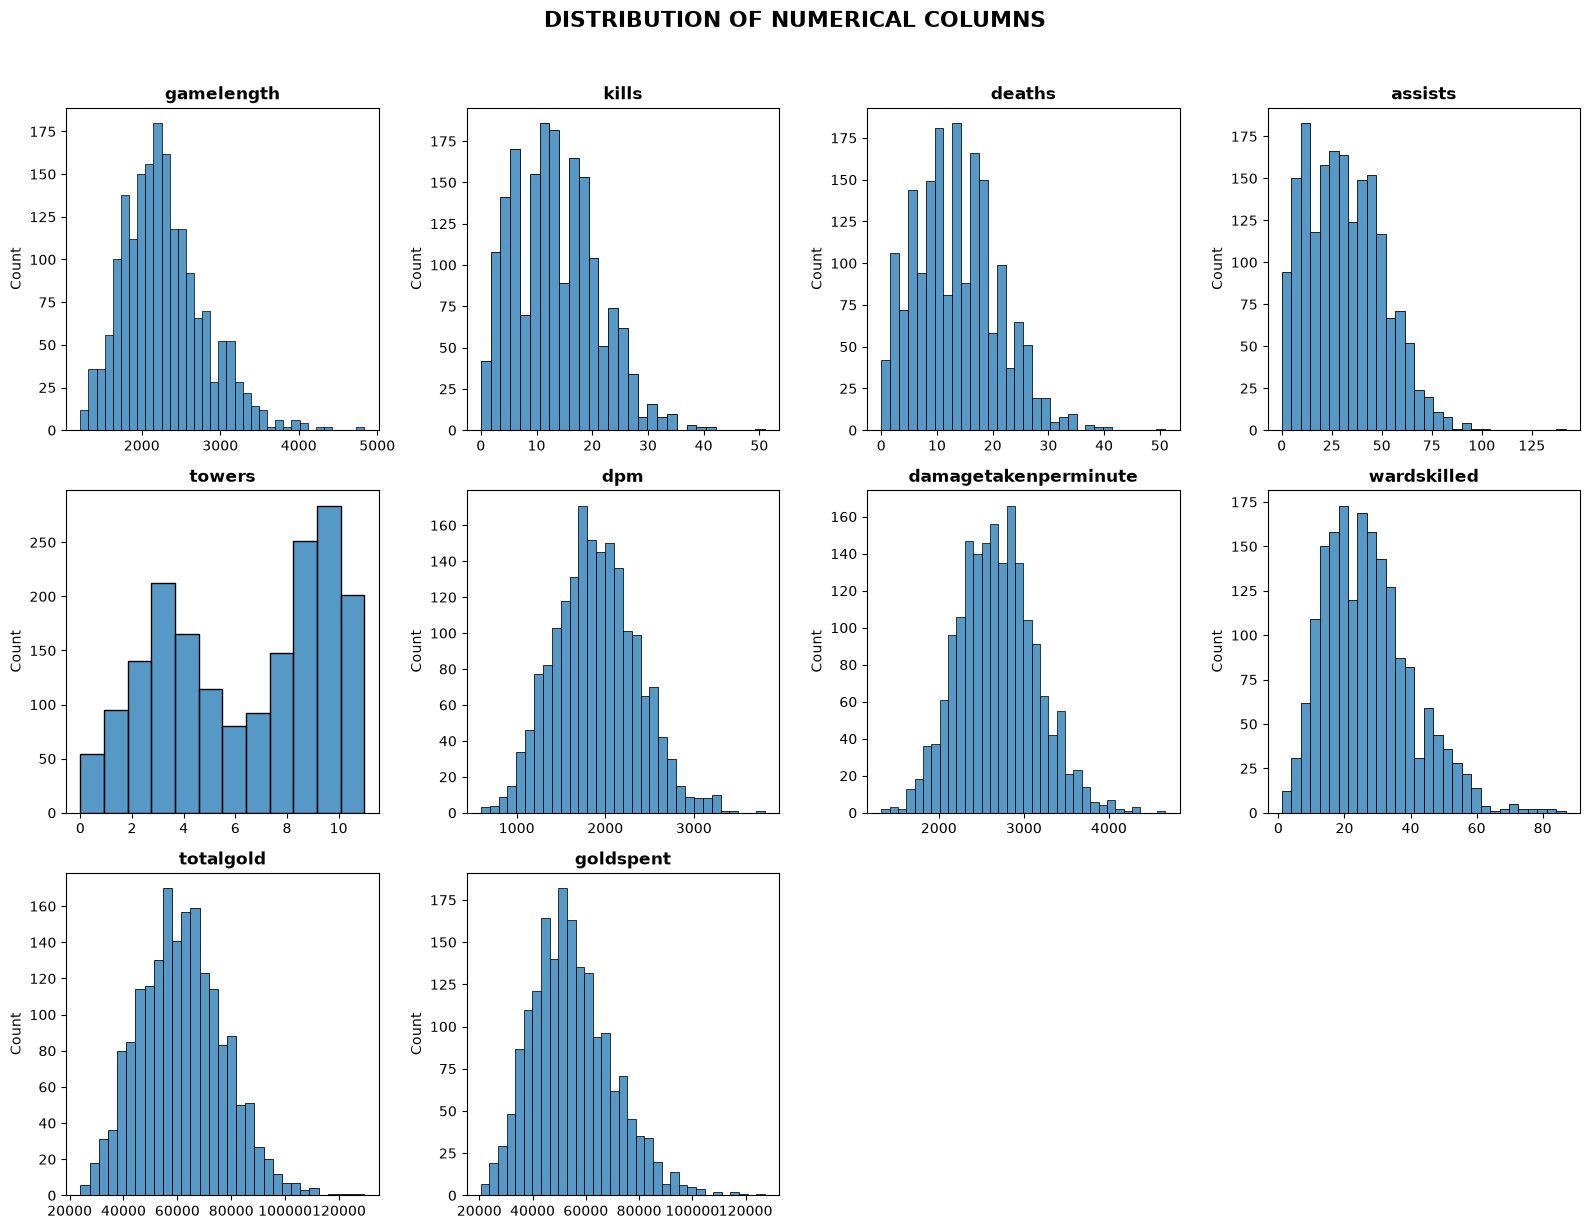

In [15]:
visualize_num_distribution(df, num_cols)

In [16]:
def visualize_cat_distribution(df, cols, plot_title="DISTRIBUTION OF CATEGORICAL DATA", nrows=3, ncols=4, figsize=(8, 6)):
    """
    Utilize bar plots to visualize categorical distribution.
    """
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize) # Adjust depending on the number of numerical columns
    axes = axes.flatten()
    fig.suptitle(plot_title.upper(), fontsize=12, fontweight="bold", y=1.02)

    for i, col in enumerate(cols):
        sns.countplot(data=df, x=col, ax=axes[i])
        axes[i].set_title(col, fontsize=12, fontweight="bold")
        axes[i].set_ylabel("")
        axes[i].tick_params(axis="x", rotation=45)

    # Hide unused subplots
    for j in range(len(cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

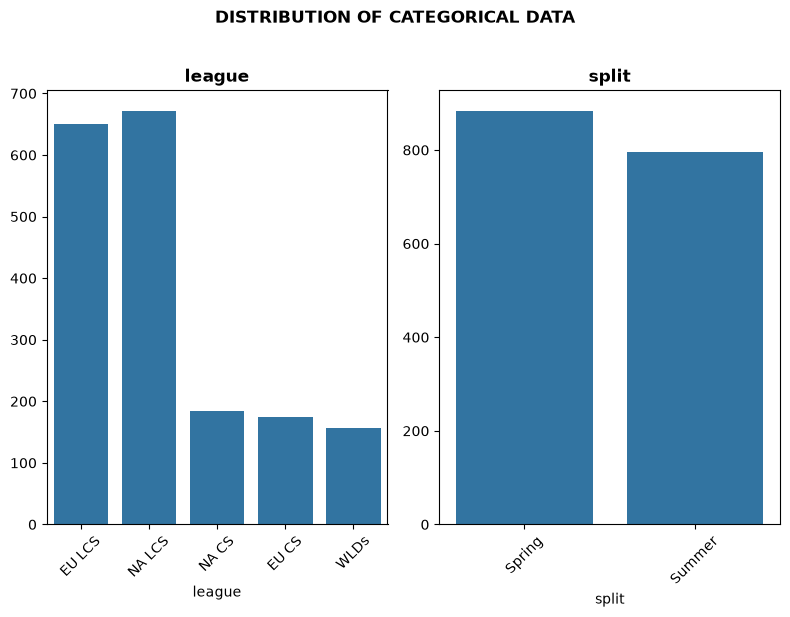

In [17]:
visualize_cat_distribution(df, cat_cols[:2], nrows=1, ncols=2)

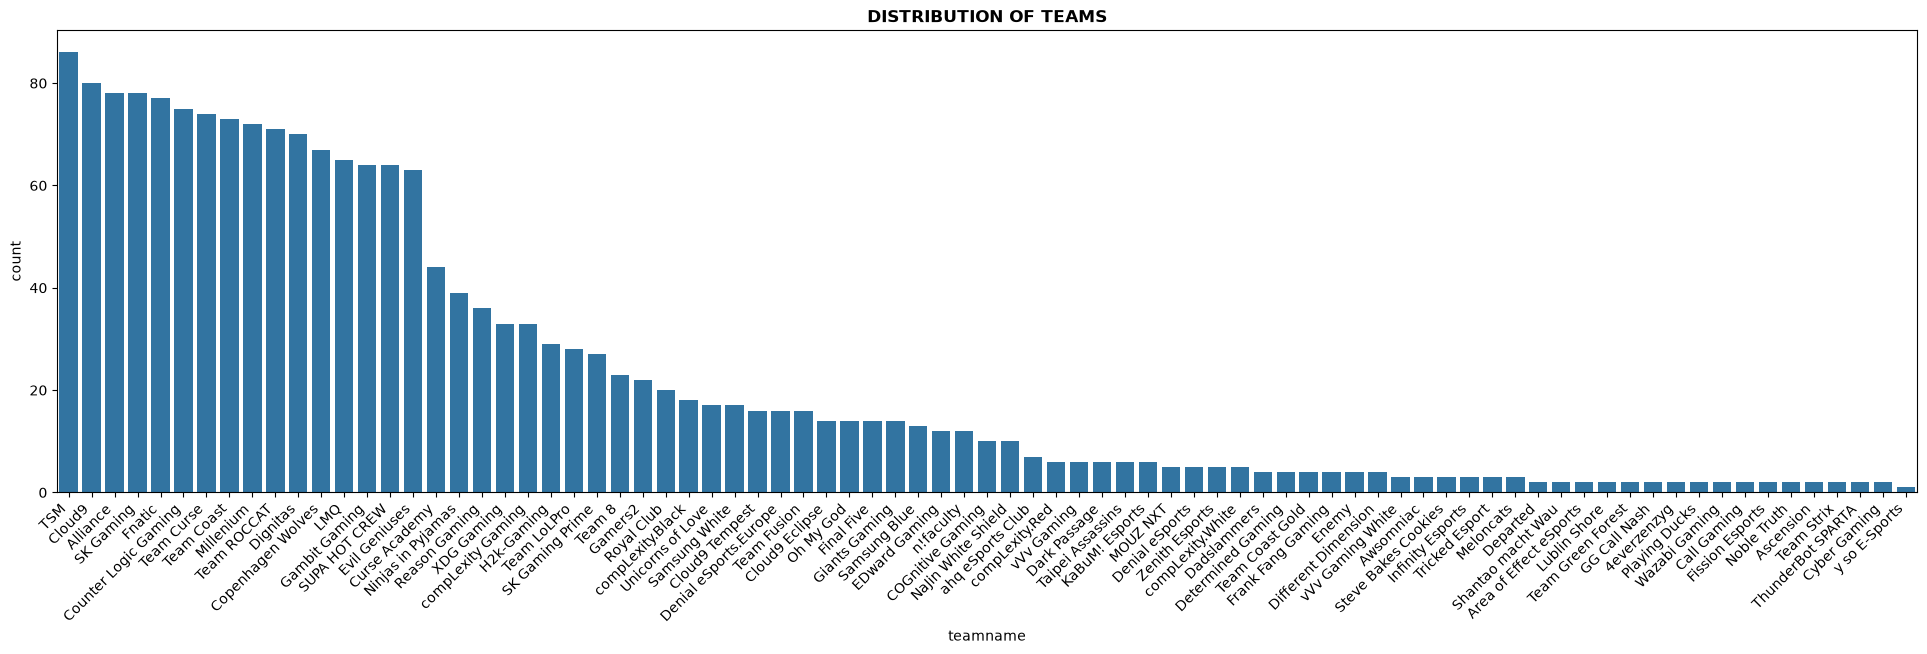

In [18]:
# Separate visualization for team names distribution
team_order = df["teamname"].value_counts().index
plt.figure(figsize=(24, 6))
sns.countplot(data=df, x='teamname', order=team_order)
plt.title('DISTRIBUTION OF TEAMS', fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.show()

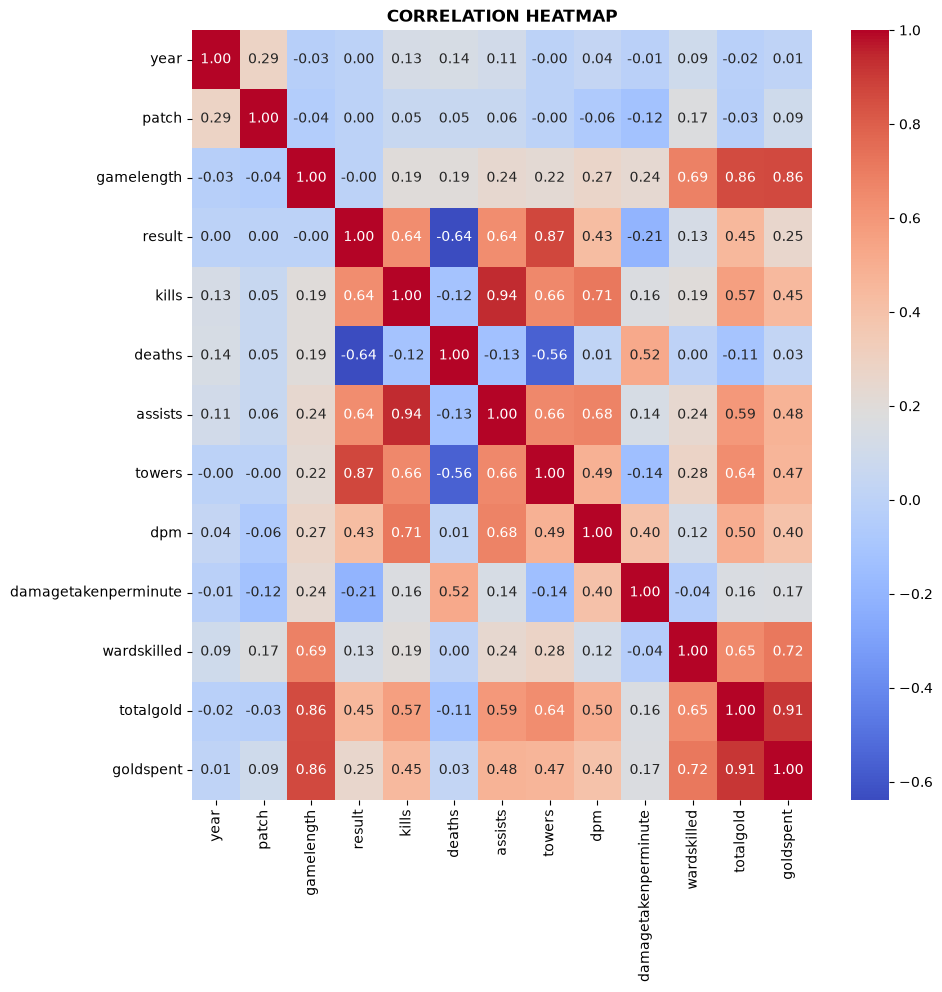

In [19]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=12, fontweight="bold")
plt.show()